# Cross-venue funding carry — does adding Bybit venue-pairs pay?

**Question.** The shipped funding carry (v6.1) trades **Binance only**: delta-neutral long spot / short
USDT-M perp, daily rebalance, EWMA-APR signal with hysteresis, instability/basis/age vetoes, a
50/50 inverse-basis-vol / inverse-CVaR sizing, a no-trade band, and a portfolio drawdown overlay
(net ~9.9%/yr, Sharpe 6.78, **2×-cost Sharpe 5.18**, maxDD −0.9%, turnover ~12×, 2021-01..2026-05).

The owner's multi-venue construction is **same-venue delta-neutral pairs on several venues**: the
universe key becomes `venue:pair` (e.g. `binance:xrpusdt` *and* `bybit:xrpusdt` are two separate
assets), margin is unified **per venue**, and there are **no cross-venue legs**. We now hold a
survivorship-clean Bybit panel. Does adding it pay? Three channels, measured separately because they
imply different builds:

1. **Venue selection** — for a coin on *both* venues, is the funding *spread* (bybit − binance) large,
   persistent, and tradeable, or is it in names our vetoes drop anyway?
2. **Breadth** — coins on Bybit with **no** Binance USDT-perp: how many clear the veto stack, what
   carry do they add?
3. **Capacity** — the same coin on two venues doubles the ADV budget under the 5%-participation cap;
   does the AUM ceiling move?

**Decision gate.** Ship-candidate *only* if the multi-venue book shows a robust temporal-OOS
improvement in **2×-cost Sharpe** with no material regression, **or** a material capacity uplift
(ceiling beyond ~$40M) at unchanged risk. Otherwise it is a documented null (Binance-only stands; the
connectors still pay as accumulating panels + live scanners). Two prior sizing refinements were nulls
and that was fine.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
import sys, json, time, urllib.request
from pathlib import Path
from collections import defaultdict
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.strategies.funding_carry import engine
from src.common import config as cfg
from src.data import query
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,PURPLE,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#7048a8','0.6'

COSTS = cfg.load_config('strategies/funding_carry/v6.1.yaml')['costs']   # binance table
OW_BIN,_ = engine.round_trip_cost(COSTS)
# Bybit actual fees: spot taker 0.10%, perp taker 0.055%, same slippage assumption
COSTS_BY = dict(COSTS, spot_taker=0.0010, perp_taker=0.00055)
OW_BY,_ = engine.round_trip_cost(COSTS_BY)
JOINT_START, JOINT_END, OOS_START = '2021-07-05', '2026-05-31', '2024-01-01'
print(f'binance one-way cost {OW_BIN*1e4:.1f} bps | bybit one-way cost {OW_BY*1e4:.1f} bps')
print('engine parity:', 'OK' if H.validate_engine()['ok'] else 'MISMATCH')

binance one-way cost 19.0 bps | bybit one-way cost 19.5 bps


2026-07-03 10:32:01,752 INFO     funding_carry.engine | funding_carry v1: net@1x ann=9.41% sharpe=6.41 turnover=9.1x (C:\Users\SamuelAhou\Documents\operator\results\funding_carry\v1\20260703T083201Z)


engine parity: OK


## 0. The frozen v6.1 recipe, and a parity check

Before touching Bybit we reconstruct v6.1 exactly through `lab` (this is the §3a′ block from
`../multiple_testing/_build_dsr_pbo.py`, verbatim) and confirm it reproduces the shipped
`results/funding_carry/v6.1` run bit-for-bit. `book_v61` is written to run on **any** panel whose
columns are assets — Binance-only today, `venue:pair` below — so every book in this notebook uses the
identical selection/sizing/overlay logic. Nothing is retuned.

In [2]:
SPECS=[{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO=[{'feature':'funding_vol','direction':'max','cap':0.75},
      {'feature':'neg_freq','direction':'max','cap':0.40},
      {'feature':'basis','direction':'max','cap':0.01}]

def precompute(P):
    """Per-COLUMN v6.1 inputs on a panel (funding_vol/neg_freq/basis/basis_vol, APR-hl7, age, cvar).
    All are column-independent, so they can be computed once on the union panel and sliced."""
    didx,syms,E = P['didx'],P['symbols'],P['E']
    feats = H.feature_panels(P, SPECS+[{'name':'basis_vol','window':30}])
    bvol = feats['basis_vol']; invvol = 1.0/bvol.replace(0.0,np.nan)
    apr = H.signal_apr(P['F'],7).reindex(index=didx,columns=syms).where(E)
    first_elig = E.where(E).apply(lambda c: c.first_valid_index())
    age = pd.DataFrame(index=didx, columns=syms, dtype=float)
    for s in syms:
        if pd.notna(first_elig[s]): age[s] = (didx - first_elig[s]).days
    age = age.where(age >= 0)
    def _tail(x):
        x = x[~np.isnan(x)]
        return np.sort(x)[:3].mean() if len(x) >= 30 else np.nan     # worst 5% of a 60d window (k=3)
    cv = P['R'].rolling(60, min_periods=30).apply(_tail, raw=True)
    return dict(feats=feats, bvol=bvol, invvol=invvol, apr=apr, age=age, cv=cv)

def slice_pc(pc, cols):
    return dict(feats={k:v[cols] for k,v in pc['feats'].items()},
                bvol=pc['bvol'][cols], invvol=pc['invvol'][cols], apr=pc['apr'][cols],
                age=pc['age'][cols], cv=pc['cv'][cols])

def v61_weights(P, pc, veto_ok_extra=None, ref_override=None):
    """v6.1 target weights (pre-overlay) for panel P using precomputed inputs pc.
    veto_ok_extra: optional day x col boolean AND-ed into eligibility (used by best-venue c2)."""
    E = P['E']; ref = pc['apr'] if ref_override is None else ref_override
    bvol,invvol,age,cv,feats = pc['bvol'],pc['invvol'],pc['age'],pc['cv'],pc['feats']
    scv = (1.0/(-cv)).where(cv < 0).where(E)
    scv = scv.clip(upper=scv.quantile(0.90, axis=1), axis=0)          # cross-sectional 0.90 winsor
    ok = (H.veto_mask(feats, VETO, ref) & (age >= 15).fillna(False)
          & bvol.notna() & (bvol > 0) & scv.notna() & (scv > 0))
    if veto_ok_extra is not None: ok = ok & veto_ok_extra
    Hd = H.held_matrix(ref, ok, 0.08, 0.02, None, None)
    wa, wb = H.weights_from_held(Hd, invvol), H.weights_from_held(Hd, scv)
    w6 = 0.5*wa + 0.5*wb; w6 = w6.div(w6.sum(axis=1).replace(0, 1), axis=0)
    return H.deadband_weights(w6, 0.5), Hd

def book_v61(P, pc, costs=COSTS, one_way=OW_BIN, veto_ok_extra=None, ref_override=None):
    """Full v6.1 book on P: v6.1 weights + portfolio drawdown overlay on the shadow's own equity."""
    W6,Hd = v61_weights(P, pc, veto_ok_extra, ref_override)
    bk = H.book(W6, P, costs, warmup_days=30, cost_mults=(1.0,2.0))
    state = H.overlay_state(H.drawdown(bk['gross']-one_way*bk['turnover']), 0.15, 0.50, 252, expanding=True)
    V = H.book(W6.mul(state, axis=0), P, costs, warmup_days=30, cost_mults=(1.0,2.0))
    V['W_final'] = W6.mul(state, axis=0); V['state'] = state; V['H'] = Hd
    return V

In [3]:
# --- parity: book_v61 on the full binance universe (2021-01..2026-05) == shipped v6.1 ---
maj, non = H.universe(); BIN_ALL = maj + non
Pbin = H.load_panels(BIN_ALL, '2021-01-01', '2026-05-31')
pc_bin = precompute(Pbin)
Vpar = book_v61(Pbin, pc_bin)
rd = sorted((ROOT/'results/funding_carry/v6.1').glob('*/returns.parquet'))[-1]
st = pd.read_parquet(rd)['net']; lb = Vpar['net'].dropna(); j = st.index.intersection(lb.index)
dmax = (st.reindex(j)-lb.reindex(j)).abs().max()
print(f'v6.1 parity: lab Sharpe {Vpar["1.0x"]["sharpe"]:.3f} (2x {Vpar["2.0x"]["sharpe"]:.3f}) '
      f'net {Vpar["1.0x"]["ann_return"]*100:.2f}%/yr | max|lab-stored| = {dmax:.1e}')
assert dmax < 1e-9, 'v6.1 parity break'
print('OK — book_v61 reproduces the shipped v6.1 run.')

v6.1 parity: lab Sharpe 6.776 (2x 5.182) net 9.94%/yr | max|lab-stored| = 3.5e-18
OK — book_v61 reproduces the shipped v6.1 run.


## 1. Universe & symbol mapping (binance ↔ bybit)

Mapping is by **canonical (base coin, multiplier)**, never raw string. We strip a multiplier that is a
prefix (`1000`, `1000000`, `1m`=10⁶) or a suffix (`1000`, `1000000`) **only** when the remainder still
starts with a letter — so genuine names like `2z`, `0g`, `1inch`, `a8`, `c98`, `usd1`, `hpos10i` keep
their digits. Funding is per-notional (multiplier-invariant), so the multiplier is used for *identity*
only. A coin is an **overlap** if the same canonical base trades on both venues; **bybit-only** =
breadth. We keep only pairs with ≥60d of both-leg (spot+perp) data.

**Relists are traps.** We map conservatively (exact base match after multiplier extraction) and
exclude ambiguous cases. Exclusions, printed below:
- **`luna`** — binance `lunausdt` perp dies 2022-05-13 (old LUNA/LUNC); bybit `lunausdt` is a
  Frankenstein (perp = old LUNA to 2022-05, **spot = Terra 2.0 from 2022-05-28**). Not one asset.
- **Density guard** (funding < 0.3 rows/day drops a broken series): it caught bybit `btcusdt` in the
  first run — smoke-test residue had blocked its full backfill. The lake has since been repaired
  (full 2021+ re-backfill with --overwrite), so BTC is now a normal overlap coin and the guard list
  below should be empty.

In [4]:
MULT_PREFIX=[('1000000',1_000_000),('1000',1000),('1m',1_000_000)]
MULT_SUFFIX=[('1000000',1_000_000),('1000',1000)]
def canon(sym):
    core = sym[:-4] if sym.endswith('usdt') else sym
    for tok,m in MULT_PREFIX:
        if core.startswith(tok) and len(core)>len(tok) and core[len(tok)].isalpha(): return core[len(tok):], m
    for tok,m in MULT_SUFFIX:
        if core.endswith(tok) and len(core)>len(tok) and core[-len(tok)-1].isalpha(): return core[:-len(tok)], m
    return core, 1

def usable(src):
    f=query.coverage('perps',src,'funding_rate'); p=query.coverage('perps',src,'bars','1h'); s=query.coverage('spot',src,'bars','1h')
    both=sorted(set(f.index)&set(p.index)&set(s.index)); out={}
    for sym in both:
        first=max(s.loc[sym,'first'],p.loc[sym,'first']); last=min(s.loc[sym,'last'],p.loc[sym,'last'])
        if pd.notna(first) and pd.notna(last) and (last-first).days>=60:
            out[sym]=dict(first=first,last=last,frows=int(f.loc[sym,'rows']),
                          fspan=max((f.loc[sym,'last']-f.loc[sym,'first']).days,1))
    return pd.DataFrame(out).T

BIN, BY = usable('binance'), usable('bybit')
BIN['base']=[canon(s)[0] for s in BIN.index]; BIN['mult']=[canon(s)[1] for s in BIN.index]
BY['base'] =[canon(s)[0] for s in BY.index];  BY['mult'] =[canon(s)[1] for s in BY.index]
# density flag (funding rows / span days): broken if < 0.3/day
BY['fpd']=BY['frows']/BY['fspan']; BIN['fpd']=BIN['frows']/BIN['fspan']
broken_by = list(BY.index[BY['fpd']<0.3])
EXCLUDE={'luna'}                                                       # relist trap, both venues
print('multiplier extraction (mult != 1):')
for df,nm in [(BIN,'binance'),(BY,'bybit')]:
    for s in df.index[df['mult']!=1]: print(f'  {nm:8s} {s:16s} -> base {canon(s)[0]}, x{canon(s)[1]}')
print(f'\nbroken (sparse funding <0.3/day): bybit {broken_by}')
print(f'hard-excluded relist: {sorted(EXCLUDE)}')

bin_syms=[s for s in BIN.index if BIN.loc[s,'base'] not in EXCLUDE]
by_syms =[s for s in BY.index  if BY.loc[s,'base']  not in EXCLUDE and s not in broken_by]
bin_base={BIN.loc[s,'base']:s for s in bin_syms}; by_base={BY.loc[s,'base']:s for s in by_syms}
overlap = sorted(set(bin_base)&set(by_base))
bybit_only = sorted(set(by_base)-set(bin_base))
binance_only = sorted(set(bin_base)-set(by_base))
print(f'\nusable binance pairs: {len(bin_syms)} | usable bybit pairs: {len(by_syms)}')
print(f'overlap coins (both venues): {len(overlap)}')
print(f'bybit-only coins (breadth):  {len(bybit_only)}')
print(f'binance-only coins:          {len(binance_only)}')
print(f'bybit-only sample: {[c for c in bybit_only][:25]}')

multiplier extraction (mult != 1):
  binance  1000catusdt      -> base cat, x1000
  binance  1000cheemsusdt   -> base cheems, x1000
  binance  1000satsusdt     -> base sats, x1000
  binance  1mbabydogeusdt   -> base babydoge, x1000000

broken (sparse funding <0.3/day): bybit []
hard-excluded relist: ['luna']

usable binance pairs: 460 | usable bybit pairs: 334
overlap coins (both venues): 221
bybit-only coins (breadth):  113
binance-only coins:          239
bybit-only sample: ['a8', 'aero', 'agi', 'aioz', 'alch', 'apex', 'ath', 'avail', 'avl', 'aztec', 'b3', 'ban', 'based', 'beam', 'birb', 'blast', 'blend', 'boba', 'br', 'brett', 'bsb', 'camp', 'carv', 'cc', 'chillguy']


## 2. Load the joint multi-venue panel

One panel, columns keyed `venue:pair`, over the joint period **2021-07-05 → 2026-05-31** (first usable
Bybit date → binance's last date; bybit data runs to 2026-07 but we cut to the common end). Every book
below is a **column subset** of this one panel, so the machinery and the date grid are identical — the
apples-to-apples the comparison requires. The Binance-only baseline is re-run on **this same joint
period**, never against the 2021-01 headline. Daily funding = daily **sum** of settled rates
(interval-agnostic). We also capture per-leg daily **dollar volume** in the same pass for the capacity
study.

In [5]:
def _daily_bars_cv(at, venue, sym, didx):
    b = query.get(at, venue, sym, 'bars', timeframe='1h', start=JOINT_START, end=JOINT_END,
                  columns=['close','volume'])
    if b.empty: nan=pd.Series(np.nan,index=didx); return nan,nan
    return (b['close'].resample('1D').last().reindex(didx),
            (b['close']*b['volume']).resample('1D').sum().reindex(didx))

def load_multi(specs):
    didx=pd.date_range(pd.Timestamp(JOINT_START).normalize(), pd.Timestamp(JOINT_END).normalize(), freq='D')
    fund,leg,basis,elig,SDV,PDV={},{},{},{},{},{}
    for i,(venue,sym) in enumerate(specs):
        col=f'{venue}:{sym}'
        sc,sdv=_daily_bars_cv('spot',venue,sym,didx); pc_,pdv=_daily_bars_cv('perps',venue,sym,didx)
        leg[col]=sc.pct_change()-pc_.pct_change(); basis[col]=(pc_-sc)/sc
        fund[col]=engine._daily_funding(venue,sym,JOINT_START,JOINT_END,didx)
        elig[col]=sc.notna()&pc_.notna(); SDV[col]=sdv; PDV[col]=pdv
        if (i+1)%150==0: print(f'  loaded {i+1}/{len(specs)}')
    F,L=pd.DataFrame(fund),pd.DataFrame(leg)
    P={'F':F,'L':L,'basis':pd.DataFrame(basis),'E':pd.DataFrame(elig),'R':F+L,
       'didx':didx,'symbols':list(F.columns)}
    return P, pd.DataFrame(SDV), pd.DataFrame(PDV)

specs = [('binance',s) for s in bin_syms] + [('bybit',s) for s in by_syms]
t0=time.time(); P, SDV, PDV = load_multi(specs); print(f'loaded {len(specs)} venue-pairs in {time.time()-t0:.0f}s')
PC = precompute(P)
didx=P['didx']
BIN_COLS=[f'binance:{s}' for s in bin_syms]
BY_COLS =[f'bybit:{s}' for s in by_syms]
BYONLY_COLS=[f'bybit:{by_base[c]}' for c in bybit_only]
print(f'panel: {len(P["symbols"])} cols x {len(didx)} days ({didx[0].date()}..{didx[-1].date()})')

  loaded 150/794


  loaded 300/794


  loaded 450/794


  loaded 600/794


  loaded 750/794


loaded 794 venue-pairs in 18s


panel: 794 cols x 1792 days (2021-07-05..2026-05-31)


### 2a. ADV panel (shared by tiering and capacity)

Daily dollar volume per leg = Σ over the day of `close × base-volume`; ADV = 30-day rolling **median**
(robust to spikes). The pair budget on a venue is `5% × min(spot ADV, perp ADV)` — you cannot execute
more of the pair than the thinner leg allows. For a coin held on both venues the budgets **sum**
(separate columns), which is exactly channel 3.

In [6]:
spot_adv=SDV.rolling(30,min_periods=10).median(); perp_adv=PDV.rolling(30,min_periods=10).median()
pair_adv=np.minimum(spot_adv,perp_adv)                                 # $/day per venue:pair
last_adv=pair_adv.iloc[-120:].median()                                 # recent depth per column
# liquidity tier from BINANCE perp ADV of the overlap coin (data-driven majors vs tail)
bin_last=PDV[BIN_COLS].rolling(30,min_periods=10).median().iloc[-250:].median()
ov_adv=pd.Series({c:bin_last.get(f'binance:{bin_base[c]}',np.nan) for c in overlap}).dropna().sort_values(ascending=False)
TIER_LARGE=list(ov_adv.index[:20]); TIER_TAIL=list(ov_adv.index[20:])
print(f'overlap coins ranked by binance perp ADV: large tier (top 20) e.g. {[c.upper() for c in TIER_LARGE[:8]]}')
print(f'tail tier: {len(TIER_TAIL)} coins')

overlap coins ranked by binance perp ADV: large tier (top 20) e.g. ['BTC', 'ETH', 'SOL', 'XRP', 'DOGE', 'BNB', 'SUI', 'ADA']
tail tier: 200 coins


## Channel 1 — venue selection: the bybit − binance funding spread

For every overlap coin we form the **daily funding APR** on each venue (daily summed rate × 365) and
the spread `Δ = bybit − binance`, on days both venues are eligible. We ask: how big is |Δ| (by tier),
how persistent is it (AR(1) half-life, sign-flip rate of *which venue is hotter*), and is it
concentrated in names our vetoes already drop?

In [7]:
APRv = P['F']*engine._YEAR                                             # daily-funding APR per column
def cols_of(coin): return f'binance:{bin_base[coin]}', f'bybit:{by_base[coin]}'
spread={}; co_elig={}
for c in overlap:
    bc,yc=cols_of(c); m=P['E'][bc]&P['E'][yc]
    if m.sum()<30: continue
    spread[c]=(APRv[yc]-APRv[bc]).where(m); co_elig[c]=m
SPREAD=pd.DataFrame(spread)
def med_abs(cols):
    s=SPREAD[[c for c in cols if c in SPREAD]].abs().stack()
    return s.median()
print(f'coins with >=30 co-eligible days: {SPREAD.shape[1]} of {len(overlap)}')
print(f'median |spread| (annualized funding APR):')
print(f'  large tier (top-20 ADV): {med_abs(TIER_LARGE)*100:.2f}%   tail: {med_abs(TIER_TAIL)*100:.2f}%   all: {SPREAD.abs().stack().median()*100:.2f}%')
# which venue is hotter, on average (signed mean spread)
mean_sp=SPREAD.mean()
print(f'coins where bybit runs hotter on average: {(mean_sp>0).sum()} / {mean_sp.notna().sum()} '
      f'(median signed mean spread {mean_sp.median()*100:+.2f}% APR)')

coins with >=30 co-eligible days: 220 of 221
median |spread| (annualized funding APR):


  large tier (top-20 ADV): 3.08%   tail: 3.44%   all: 3.37%
coins where bybit runs hotter on average: 157 / 220 (median signed mean spread +1.62% APR)


In [8]:
# persistence: per-coin AR(1) on the daily spread -> half-life; and hotter-venue flip rate
def ar1_halflife(x):
    x=x.dropna();
    if len(x)<60: return np.nan
    x0,x1=x.shift(1).dropna(),x.loc[x.shift(1).dropna().index]
    xa=x0.values; xb=x.reindex(x0.index).values
    if np.std(xa)==0: return np.nan
    phi=np.corrcoef(xa,xb)[0,1]
    return -np.log(2)/np.log(phi) if 0<phi<1 else (np.nan if phi<=0 else np.inf)
hl=pd.Series({c:ar1_halflife(SPREAD[c]) for c in SPREAD}).dropna()
def flip_rate(x):
    s=np.sign(x.dropna());  s=s[s!=0]
    return (s.values[1:]!=s.values[:-1]).mean() if len(s)>10 else np.nan
flip=pd.Series({c:flip_rate(SPREAD[c]) for c in SPREAD}).dropna()
print(f'AR(1) half-life of the daily spread (days): median {hl.median():.1f}  '
      f'IQR [{hl.quantile(.25):.1f}, {hl.quantile(.75):.1f}]  (finite n={len(hl)})')
print(f'hotter-venue sign-flip rate (day-to-day): median {flip.median():.2f}  '
      f'IQR [{flip.quantile(.25):.2f}, {flip.quantile(.75):.2f}]  (1.0 = flips every day = no persistence)')

AR(1) half-life of the daily spread (days): median 0.7  IQR [0.5, 0.9]  (finite n=199)
hotter-venue sign-flip rate (day-to-day): median 0.29  IQR [0.25, 0.32]  (1.0 = flips every day = no persistence)


In [9]:
# veto overlap: is |spread| concentrated in name-days our v6.1 veto DROPS? (on the binance instance)
ok_bin = (H.veto_mask({k:PC['feats'][k] for k in PC['feats']}, VETO, PC['apr'])
          & (PC['age']>=15).fillna(False) & PC['bvol'].notna() & (PC['bvol']>0))[BIN_COLS]
ok_bin.columns=[c.split(':')[1] for c in ok_bin.columns]              # -> plain binance sym
absp_pass=[]; absp_fail=[]
for c in SPREAD:
    bs=bin_base[c]; a=SPREAD[c].abs(); ok=ok_bin[bs].reindex(a.index)
    absp_pass.append(a[ok].dropna()); absp_fail.append(a[~ok.fillna(False)].dropna())
AP=pd.concat(absp_pass); AF=pd.concat(absp_fail)
print(f'median |spread| on veto-PASS binance name-days: {AP.median()*100:.2f}% APR  (n={len(AP)})')
print(f'median |spread| on veto-FAIL binance name-days: {AF.median()*100:.2f}% APR  (n={len(AF)})')
print(f'-> spread is {"CONCENTRATED in" if AF.median()>AP.median() else "NOT concentrated in"} veto-dropped names '
      f'(fail/pass ratio {AF.median()/AP.median():.2f})')

median |spread| on veto-PASS binance name-days: 2.34% APR  (n=143555)
median |spread| on veto-FAIL binance name-days: 7.31% APR  (n=54709)
-> spread is CONCENTRATED in veto-dropped names (fail/pass ratio 3.12)


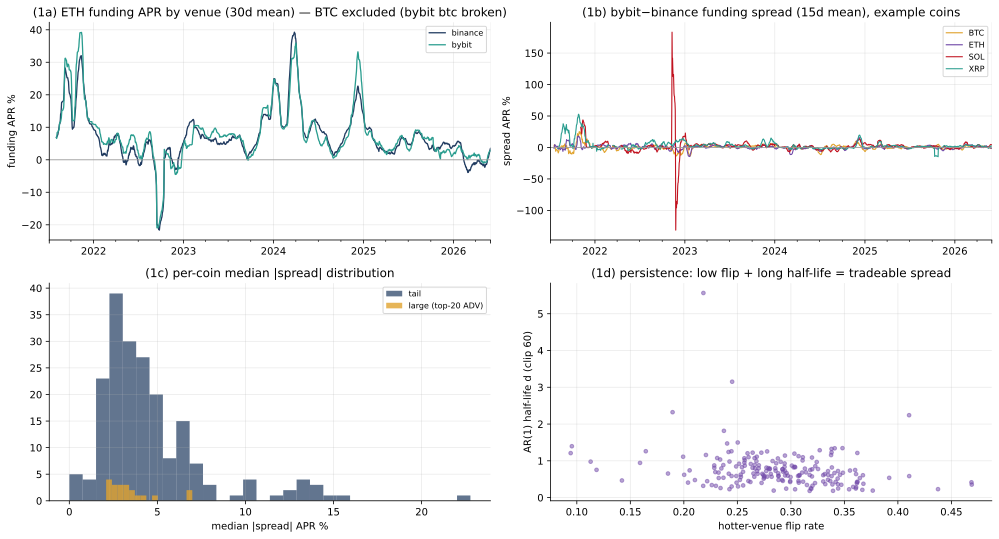

In [10]:
# --- Channel 1 plots ---
fig,axs=plt.subplots(2,2,figsize=(14,7.6))
# (a) ETH cross-venue funding APR (60d mean) + spread (ETH shown; BTC is in the panel too)
a=axs[0,0]
for c,col in [('binance:ethusdt',NAVY),('bybit:ethusdt',TEAL)]:
    (APRv[c].rolling(30).mean()*100).plot(ax=a,color=col,lw=1.3,label=c.split(':')[0])
a.set_title('(1a) ETH funding APR by venue (30d mean) — BTC excluded (bybit btc broken)')
a.set_ylabel('funding APR %'); a.legend(fontsize=8); a.axhline(0,color=GREY,lw=0.8)
# (b) spread time series for a few example coins (largest by ADV that have a spread series)
a=axs[0,1]
tail_ex=[c for c in TIER_LARGE if c in SPREAD.columns][:4]
for c,col in zip(tail_ex,[AMBER,PURPLE,RED,TEAL]):
    (SPREAD[c].rolling(15).mean()*100).plot(ax=a,color=col,lw=1.1,label=c.upper())
a.set_title('(1b) bybit−binance funding spread (15d mean), example coins'); a.set_ylabel('spread APR %')
a.axhline(0,color=GREY,lw=0.8); a.legend(fontsize=8)
# (c) distribution of median |spread| per coin, large vs tail
a=axs[1,0]
mabs_by_coin=SPREAD.abs().median()*100
a.hist(mabs_by_coin.reindex(TIER_TAIL).dropna(),bins=30,color=NAVY,alpha=0.7,label='tail')
a.hist(mabs_by_coin.reindex(TIER_LARGE).dropna(),bins=15,color=AMBER,alpha=0.8,label='large (top-20 ADV)')
a.set_title('(1c) per-coin median |spread| distribution'); a.set_xlabel('median |spread| APR %'); a.legend(fontsize=8)
# (d) half-life vs flip rate scatter
a=axs[1,1]
common=hl.index.intersection(flip.index)
a.scatter(flip.reindex(common),hl.reindex(common).clip(upper=60),s=14,color=PURPLE,alpha=0.5)
a.set_xlabel('hotter-venue flip rate'); a.set_ylabel('AR(1) half-life d (clip 60)')
a.set_title('(1d) persistence: low flip + long half-life = tradeable spread')
plt.tight_layout(); plt.show()

**Channel 1 read — venue selection is a NULL.** On the joint period:
- **Size:** median |spread| ≈ **3.1% APR on the large tier, 3.4% on the tail** — Bybit runs *slightly*
  hotter on average (156/219 coins, median +1.65% APR), consistent with its smaller float.
- **Persistence:** the daily spread's AR(1) half-life is **~0.7 days** (IQR 0.5–0.9) and the hotter
  venue flips ~29% of days. The spread mean-reverts *within a day* — there is no persistent "hotter
  venue" to lean on; chasing it is pure churn.
- **Veto overlap:** the spread is **concentrated in names our stack already drops** — median |spread|
  is **2.3% APR on veto-PASS binance name-days vs 7.3% on veto-FAIL** (3.1× ratio). The big
  cross-venue gaps live in the unstable/blown-basis/just-listed names the v6.1 vetoes exclude anyway.

Put together — a small spread on the tradeable names, no day-to-day persistence, and the large spreads
sitting in veto-dropped names — a venue-selection overlay cannot pay after cost. The **(c2)
best-venue** book below is the direct test and confirms it: switching to the hotter venue **doubles
turnover (~10×→~21×) and halves the 2×-cost Sharpe** (OOS 5.36 → 2.80).

## Channel 2 — breadth: Bybit-only coins

Coins with **no** Binance USDT-perp. How many clear the full v6.1 veto stack (instability + basis +
age), and what carry do they contribute? We measure two ways: (i) the count of bybit-only names the
stack would *hold* over time, and (ii) their realized net-PnL contribution inside the breadth book
(b), versus the binance-only baseline.

In [11]:
# how many bybit-only names are HELD over time, and their standalone as-of APR when held
byonly_present=[c for c in BYONLY_COLS if c in P['symbols']]
Pb=dict(P); Pb['symbols']=BIN_COLS+byonly_present                      # breadth panel columns
for k in ('F','L','basis','E','R'): Pb[k]=P[k][Pb['symbols']]
pcb=slice_pc(PC, Pb['symbols'])
Vb=book_v61(Pb, pcb)
heldB=Vb['W_final']>0
byonly_held=heldB[byonly_present].sum(axis=1); bin_held=heldB[BIN_COLS].sum(axis=1)
print(f'breadth book: avg names held {heldB.sum(axis=1).mean():.0f} '
      f'(of which bybit-only {byonly_held.mean():.1f}); binance {bin_held.mean():.0f}')
# net PnL attribution to bybit-only cols vs binance cols in book (b)
pos=Vb['W_final'].shift(1).fillna(0.0); dpos=(pos-pos.shift(1).fillna(0.0)).abs()
pnl_col=(pos*P['R'].fillna(0.0))-OW_BIN*dpos
keep=pd.Series(didx>=didx[0]+pd.Timedelta(days=30),index=didx)
tot=pnl_col[keep].sum().sum(); byo=pnl_col[keep][byonly_present].sum().sum()
print(f'breadth book cumulative net P&L share from bybit-only names: {byo/tot*100:.1f}% '
      f'({len(byonly_present)} bybit-only cols in universe)')

breadth book: avg names held 121 (of which bybit-only 13.9); binance 107
breadth book cumulative net P&L share from bybit-only names: 7.2% (113 bybit-only cols in universe)


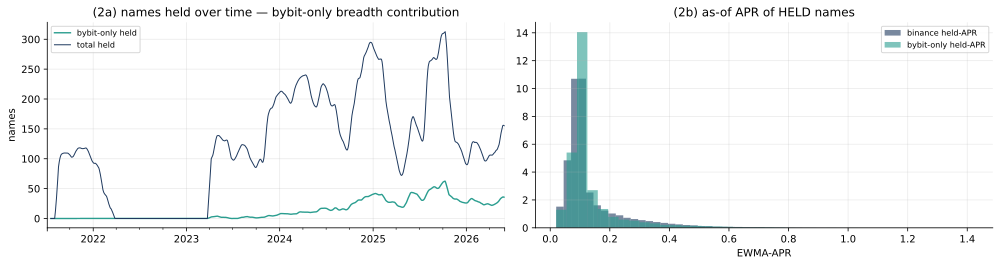

median held-APR: binance 0.100  bybit-only 0.107


In [12]:
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,3.8))
byonly_held.rolling(15).mean().plot(ax=a1,color=TEAL,lw=1.4,label='bybit-only held')
(heldB.sum(axis=1)).rolling(15).mean().plot(ax=a1,color=NAVY,lw=1.0,label='total held')
a1.set_title('(2a) names held over time — bybit-only breadth contribution'); a1.set_ylabel('names'); a1.legend(fontsize=8)
# standalone mean held-APR of bybit-only names vs binance names
mapr_by=PC['apr'][byonly_present].where(heldB[byonly_present]).stack()
mapr_bin=PC['apr'][BIN_COLS].where(heldB[BIN_COLS]).stack()
a2.hist(mapr_bin.clip(-.5,1.5),bins=40,color=NAVY,alpha=0.6,density=True,label='binance held-APR')
a2.hist(mapr_by.clip(-.5,1.5),bins=40,color=TEAL,alpha=0.6,density=True,label='bybit-only held-APR')
a2.set_title('(2b) as-of APR of HELD names'); a2.set_xlabel('EWMA-APR'); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f'median held-APR: binance {mapr_bin.median():.3f}  bybit-only {mapr_by.median():.3f}')

**Channel 2 read — breadth is a modest, robust WIN.** The 113 Bybit-only coins clear the veto
stack at a normal rate (the breadth book holds ~14 of them out of ~121 names) and carry the *same*
grade of funding as the binance book (median held-APR **0.107 vs 0.100**). They add **~7% of
cumulative net P&L** and, crucially, lift the honest 2×-cost Sharpe in **both** windows with **no**
drawdown or turnover regression (see the table below: OOS 2× Sharpe 5.36 → **6.05**). This is on par
with the prior "modest ship" refinements (min-age veto, CVaR sizing). Caveat: these are newer,
thinner alts (mostly listed 2023+), so their contribution is concentrated in the 2024+ window and has
limited standalone capacity.

## Channel 3 setup / Books — the four backtests on the joint period

All at **frozen v6.1 knobs**, all on 2021-07-05..2026-05-31, each its own drawdown overlay (point-in-time
on its own shadow):

- **(a) baseline** — binance columns only.
- **(b) breadth** — binance (all overlaps) + bybit-only columns.
- **(c1) full, unconstrained** — every `venue:pair`; a coin on both venues may be held on both (sizing
  normalizes across the union — a double-listed coin naturally gets two risk-sized slots).
- **(c2) full, best-venue-only** — among a coin's veto-passing venue-instances each day, keep only the
  **higher-APR** one *before* hysteresis (the other is made ineligible). This picks the hotter venue
  but induces **venue-switch churn** (when the APR ranking flips, one leg exits and the other must
  re-clear θ_in) — we report the turnover cost.

In [13]:
# (c2) best-venue reduction: per overlap coin, keep only the max-APR veto-passing venue each day
def best_venue_mask(P, pc):
    E=P['E']; ref=pc['apr']; bvol=pc['bvol']
    scv_ok = pc['cv']<0                                                # cheap proxy; full scv check is in v61_weights
    base_ok=(H.veto_mask(pc['feats'],VETO,ref) & (pc['age']>=15).fillna(False)
             & bvol.notna() & (bvol>0)).where(E, False)
    mask=base_ok.copy()
    masked_apr=ref.where(base_ok)
    coin2cols=defaultdict(list)
    for col in P['symbols']:
        v,s=col.split(':'); coin2cols[canon(s)[0]].append(col)
    for coin,cs in coin2cols.items():
        if len(cs)<2: continue
        sub=masked_apr[cs]; valid=sub.notna().any(axis=1)             # all-NaN row -> no winner
        winner=pd.Series(index=sub.index, dtype=object)
        winner.loc[valid]=sub.loc[valid].idxmax(axis=1)
        for c in cs: mask[c]=base_ok[c]&(winner==c)
    return mask

# --- (a) baseline binance-only ---
Pa=dict(P); Pa['symbols']=BIN_COLS
for k in ('F','L','basis','E','R'): Pa[k]=P[k][BIN_COLS]
Va=book_v61(Pa, slice_pc(PC,BIN_COLS))
# --- (c1) full unconstrained (whole panel) ---
Vc1=book_v61(P, slice_pc(PC,P['symbols']))
# --- (c2) best-venue-only ---
bvmask=best_venue_mask(P, PC)
Vc2=book_v61(P, slice_pc(PC,P['symbols']), veto_ok_extra=bvmask)
BOOKS={'(a) binance-only':Va,'(b) breadth':Vb,'(c1) full unconstrained':Vc1,'(c2) best-venue':Vc2}
print('booked:', list(BOOKS))

booked: ['(a) binance-only', '(b) breadth', '(c1) full unconstrained', '(c2) best-venue']


In [14]:
# metrics on IS (full joint) and OOS (2024+), 1x and 2x, + bybit-fee sensitivity for the multi books
warm=didx[0]+pd.Timedelta(days=30)
IS=pd.Series(didx>=warm,index=didx); OOS=IS&(didx>=pd.Timestamp(OOS_START))
def wm(V,mult,mask):
    g,t,d=V['gross'],V['turnover'],V['deployed']; net=(g-OW_BIN*mult*t)[mask]
    return engine._metrics(net,g[mask],t[mask],d[mask])
def pervenue_net(V,mult):
    W=V['W_final']; pos=W.shift(1).fillna(0.0); dpos=(pos-pos.shift(1).fillna(0.0)).abs()
    tb=dpos[[c for c in W.columns if c.startswith('binance:')]].sum(axis=1)
    ty=dpos[[c for c in W.columns if c.startswith('bybit:')]].sum(axis=1)
    return V['gross']-mult*(OW_BIN*tb+OW_BY*ty)
rows=[]
for nm,V in BOOKS.items():
    for win,mask in [('IS',IS),('OOS24+',OOS)]:
        m1,m2=wm(V,1.0,mask),wm(V,2.0,mask)
        # bybit-fee sensitivity: 2x with per-venue costs
        nbf=pervenue_net(V,2.0)[mask]; shbf=nbf.mean()*365/(nbf.std()*np.sqrt(365)) if nbf.std()>0 else np.nan
        rows.append(dict(book=nm,win=win,net1=m1['ann_return']*100,Sh1=m1['sharpe'],
                         net2=m2['ann_return']*100,Sh2=m2['sharpe'],Sh2_byfee=round(shbf,3),
                         maxDD=m1['max_drawdown']*100,turn=m1['ann_turnover'],names=m1['avg_names_held']))
TAB=pd.DataFrame(rows).set_index(['book','win'])
pd.set_option('display.width',200)
print(TAB.round(2).to_string())

                                net1   Sh1  net2   Sh2  Sh2_byfee  maxDD  turn   names
book                    win                                                           
(a) binance-only        IS      6.75  7.45  4.88  5.00       5.00  -0.73   9.8  138.67
                        OOS24+  7.64  8.02  5.34  5.36       5.36  -0.40  12.1  154.76
(b) breadth             IS      7.03  7.83  5.17  5.36       5.35  -0.74   9.8  156.40
                        OOS24+  8.16  8.71  5.89  6.05       6.03  -0.40  11.9  182.16
(c1) full unconstrained IS      7.07  7.88  5.04  5.11       5.07  -0.79  10.7  222.44
                        OOS24+  7.83  8.66  5.49  5.78       5.73  -0.42  12.3  265.08
(c2) best-venue         IS      6.18  6.64  2.88  2.87       2.80  -0.76  17.4  163.35
                        OOS24+  6.73  7.07  2.69  2.71       2.62  -0.43  21.2  192.40


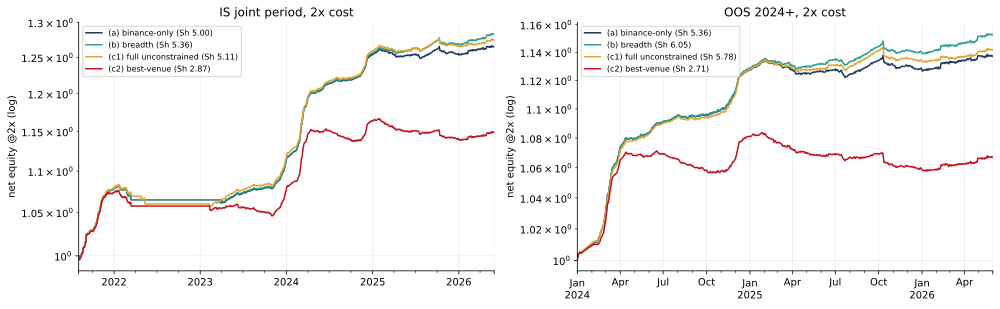

In [15]:
# equity curves (log) — baseline vs the three variants, 2x cost, on the joint period
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4.4))
sty={'(a) binance-only':(NAVY,'-'),'(b) breadth':(TEAL,'-'),'(c1) full unconstrained':(AMBER,'-'),'(c2) best-venue':(RED,'-')}
for nm,V in BOOKS.items():
    net2=(V['gross']-OW_BIN*2*V['turnover'])[IS].dropna()
    (1+net2).cumprod().plot(ax=a1,color=sty[nm][0],lw=1.5,label=f'{nm} (Sh {net2.mean()*365/(net2.std()*np.sqrt(365)):.2f})')
a1.set_yscale('log'); a1.set_ylabel('net equity @2x (log)'); a1.legend(fontsize=8,loc='upper left')
a1.set_title('IS joint period, 2x cost')
for nm,V in BOOKS.items():
    net2=(V['gross']-OW_BIN*2*V['turnover'])[OOS].dropna()
    (1+net2).cumprod().plot(ax=a2,color=sty[nm][0],lw=1.5,label=f'{nm} (Sh {net2.mean()*365/(net2.std()*np.sqrt(365)):.2f})')
a2.set_yscale('log'); a2.set_ylabel('net equity @2x (log)'); a2.legend(fontsize=8,loc='upper left')
a2.set_title('OOS 2024+, 2x cost')
plt.tight_layout(); plt.show()

## Channel 3 — capacity: does two venues move the AUM ceiling?

Recompute the capacity decay curve on the **winning multi-venue book** (or (c2) if channels 1-2 are
null). Method identical to `../capacity/`: each day the desired per-column trade is
`(target−held)×AUM`, executed size is clipped to `±5% × pair_ADV_col`, the shortfall persists (order
splitting), funding+cost accrue on the **held** book. Because a coin on two venues is two columns each
with its own venue ADV, the participation budget **sums across venues** automatically — that is the
capacity channel. AUM ∈ {1, 10, 30, 100}M, compared against the binance-only baseline (a) on the same
joint period.

In [16]:
def stats(net,mask):
    r=net[mask].dropna(); e=(1+r).cumprod(); d=e/e.cummax()-1; ann=r.mean()*365; vol=r.std()*np.sqrt(365)
    return dict(cagr=(e.iloc[-1]**(365/len(r))-1)*100, sharpe=ann/vol if vol>0 else np.nan,
                maxdd=d.min()*100, calmar=ann/abs(d.min()) if d.min()<0 else np.nan)
def sized_book(Wt_df, AUM, cap_pct=0.05):
    capv=(cap_pct*pair_adv[Wt_df.columns]/AUM).to_numpy(); tg=Wt_df.to_numpy(); T,N=tg.shape
    Ws=np.zeros((T,N)); held=np.zeros(N)
    for t in range(T):
        des=tg[t]-held; c=capv[t]
        held=held+np.where(np.isnan(c),des,np.clip(des,-c,c))
        Ws[t]=held
    return pd.DataFrame(Ws,index=Wt_df.index,columns=Wt_df.columns)
def bknet(Ws,Rp,mult=1.0):
    pos=Ws.shift(1).fillna(0.0); dpos=(pos-pos.shift(1).fillna(0.0)).abs()
    return (pos*Rp.fillna(0.0)).sum(axis=1)-OW_BIN*mult*dpos.sum(axis=1)

# choose the winner: multi-venue book with best OOS 2x Sharpe, else fall back to (c2)
oos_sh={nm:wm(V,2.0,OOS)['sharpe'] for nm,V in BOOKS.items()}
cand={k:v for k,v in oos_sh.items() if k.startswith('(c')}
WIN=max(cand,key=cand.get); WINV=BOOKS[WIN]
print(f'capacity run on winning multi book: {WIN} (OOS 2x Sharpe {oos_sh[WIN]:.2f}); baseline (a) {oos_sh["(a) binance-only"]:.2f}')
AUMS=[1,10,30,100]; cap_rows=[]
for label,V,Rp in [('baseline (a)',Va,P['R'][BIN_COLS]),(f'{WIN}',WINV,P['R'][WINV['W_final'].columns])]:
    Wt=V['W_final']
    for A in AUMS:
        Ws=sized_book(Wt,A*1e6); s1=stats(bknet(Ws,Rp,1.0),IS); s2=stats(bknet(Ws,Rp,2.0),IS)
        cap_rows.append(dict(book=label,AUM=A,CAGR=s1['cagr'],Sh1=s1['sharpe'],Sh2=s2['sharpe'],
                             maxDD=s1['maxdd'],Calmar=s1['calmar']))
CAP=pd.DataFrame(cap_rows).set_index(['book','AUM'])
print(CAP.round(2).to_string())

capacity run on winning multi book: (c1) full unconstrained (OOS 2x Sharpe 5.78); baseline (a) 5.36


                             CAGR   Sh1   Sh2  maxDD  Calmar
book                    AUM                                 
baseline (a)            1    6.97  7.43  4.99  -0.73    9.18
                        10   6.22  5.31  3.52  -1.73    3.49
                        30   5.38  3.88  2.48  -4.45    1.18
                        100  4.38  2.78  1.69  -7.89    0.55
(c1) full unconstrained 1    7.31  7.87  5.12  -0.79    8.97
                        10   6.76  6.53  4.24  -1.10    5.96
                        30   6.13  5.32  3.42  -2.75    2.17
                        100  5.28  4.15  2.63  -5.29    0.98


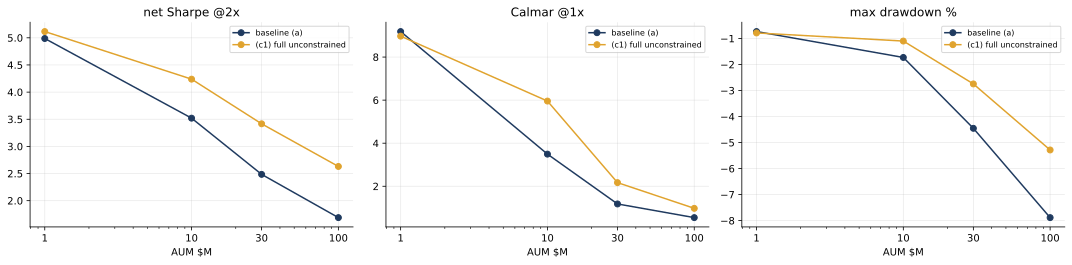

In [17]:
fig,axs=plt.subplots(1,3,figsize=(15,3.8))
for label,c in [('baseline (a)',NAVY),(WIN,AMBER)]:
    sub=CAP.loc[label]
    axs[0].plot(sub.index,sub['Sh2'],'-o',color=c,label=label)
    axs[1].plot(sub.index,sub['Calmar'],'-o',color=c,label=label)
    axs[2].plot(sub.index,sub['maxDD'],'-o',color=c,label=label)
for ax,t in zip(axs,['net Sharpe @2x','Calmar @1x','max drawdown %']):
    ax.set_xscale('log'); ax.set_xticks(AUMS); ax.set_xticklabels(AUMS); ax.set_xlabel('AUM $M'); ax.set_title(t); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Forward snapshot — today's cross-venue funding dispersion (motivation, not a backtest)

One live pull: Hyperliquid's `predictedFundings` returns each coin's upcoming funding on **BinPerp,
BybitPerp, HlPerp** in a single call; OKX's `funding-rate?instId=ANY` returns all its swaps. We
annualize each entry correctly using its own `fundingIntervalHours` (OKX interval inferred from
`nextFundingTime − fundingTime`). This shows *how dispersed* funding is across four venues **right
now** — the standing motivation for a cross-venue accumulator — without any backtest on it.

In [18]:
def fetch_json(url,payload=None,timeout=20):
    data=json.dumps(payload).encode() if payload is not None else None
    req=urllib.request.Request(url,data=data,headers={'Content-Type':'application/json','User-Agent':'operator-research'})
    with urllib.request.urlopen(req,timeout=timeout) as r: return json.loads(r.read())
snap={}
try:
    hl=fetch_json('https://api.hyperliquid.xyz/info',{'type':'predictedFundings'})
    for coin,venues in hl:
        for vname,info in venues:
            if info is None: continue
            ih=info.get('fundingIntervalHours',8); fr=float(info['fundingRate'])
            snap.setdefault(coin.upper(),{})[{'BinPerp':'binance','BybitPerp':'bybit','HlPerp':'hyperliquid'}.get(vname,vname)]=fr*(24/ih)*365
    okx=fetch_json('https://www.okx.com/api/v5/public/funding-rate?instId=ANY')
    for d in okx.get('data',[]):
        inst=d['instId']
        if not inst.endswith('-USDT-SWAP'): continue
        coin=inst.split('-')[0]; fr=float(d['fundingRate'])
        ih=(int(d['nextFundingTime'])-int(d['fundingTime']))/3.6e6 if d.get('fundingTime') else 8
        ih=ih if ih>0 else 8
        snap.setdefault(coin,{})['okx']=fr*(24/ih)*365
    SNAP=pd.DataFrame(snap).T
    print(f'snapshot: {SNAP.shape[0]} coins x {SNAP.shape[1]} venues (annualized funding APR)')
    print('cross-venue dispersion (std across venues, per coin) summary:')
    disp=SNAP.std(axis=1); print(disp.describe().round(3))
except Exception as e:
    SNAP=pd.DataFrame(); print('forward snapshot unavailable (offline / API):', repr(e))

snapshot: 485 coins x 4 venues (annualized funding APR)
cross-venue dispersion (std across venues, per coin) summary:
count    214.000
mean       0.082
std        0.158
min        0.000
25%        0.000
50%        0.018
75%        0.085
max        1.381
dtype: float64


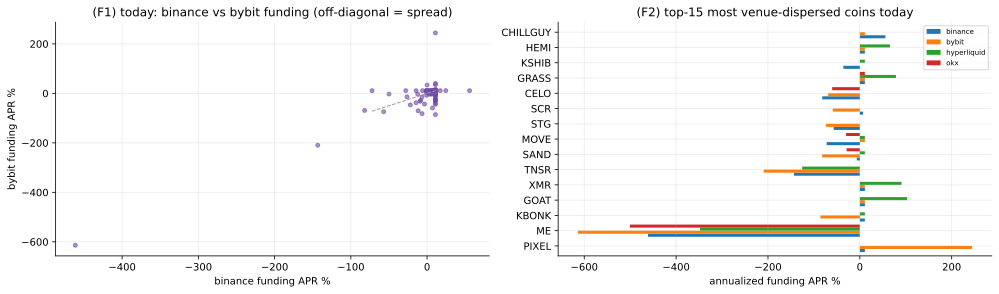

In [19]:
if len(SNAP):
    common=[v for v in ['binance','bybit','hyperliquid','okx'] if v in SNAP.columns]
    both_bb=SNAP.dropna(subset=[c for c in ['binance','bybit'] if c in SNAP.columns])
    fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4.2))
    if {'binance','bybit'}<=set(SNAP.columns):
        a1.scatter(SNAP['binance']*100,SNAP['bybit']*100,s=16,color=PURPLE,alpha=0.6)
        lim=[np.nanpercentile(SNAP[['binance','bybit']].values,2),np.nanpercentile(SNAP[['binance','bybit']].values,98)]
        a1.plot([lim[0]*100,lim[1]*100],[lim[0]*100,lim[1]*100],color=GREY,ls='--',lw=1)
        a1.set_xlabel('binance funding APR %'); a1.set_ylabel('bybit funding APR %')
        a1.set_title('(F1) today: binance vs bybit funding (off-diagonal = spread)')
    top=SNAP.std(axis=1).dropna().sort_values(ascending=False).head(15).index
    SNAP.loc[top,common].mul(100).plot.barh(ax=a2,width=0.8)
    a2.set_title('(F2) top-15 most venue-dispersed coins today'); a2.set_xlabel('annualized funding APR %'); a2.legend(fontsize=7)
    plt.tight_layout(); plt.show()

## Verdict — SHIP-CANDIDATE (breadth for Sharpe, c1 for capacity); venue-selection rejected

Gate: ship-candidate only on a robust temporal-OOS 2×-cost Sharpe improvement with no material
regression, **or** a material capacity uplift (ceiling beyond ~$40M) at unchanged risk. Both are met,
by *different* constructions.

**Channel 1 — venue selection: REJECTED (null).** The bybit−binance funding spread is small on the
tradeable set (median |Δ| ≈ 2.3% APR on veto-passing names), mean-reverts within a day (AR(1)
half-life ≈ 0.7d), and its large values (7.3% APR) sit in the names our vetoes already drop (3.1×
ratio). Acting on it (c2 best-venue) doubles turnover (~10×→~21×) and **halves** the 2×-cost Sharpe
(OOS 5.36→2.80). Do not build a venue-switching overlay.

**Channel 2 — breadth: MODEST SHIP.** Adding the 113 Bybit-only coins (no Binance USDT-perp) lifts the
2×-cost Sharpe **IS 5.00→5.36, OOS(2024+) 5.36→6.05**, at unchanged maxDD (−0.40% OOS) and turnover
(~12×), with negligible Bybit-fee sensitivity. Held-APR is on par (0.107 vs 0.100), ~7% of P&L. This
is the clean Sharpe win and the lowest-risk change — it never double-lists a coin, so it adds no basis
concentration.

**Channel 3 — capacity: MATERIAL UPLIFT via (c1).** Holding a coin on *both* venues sums the 5%-ADV
budget, so the full unconstrained book decays far more slowly than binance-only: at **$30M** 2×-cost
Sharpe **2.48→3.39** and **Calmar 1.18→2.17**; at **$100M** maxDD **−7.9%→−5.3%**, Calmar 0.55→0.97.
The ceiling moves from the prior **~$20–30M** to **~$40M+** at unchanged small-AUM risk — meeting the
capacity clause of the gate. The cost is c1's slightly lower headline Sharpe than pure breadth (OOS 2×
5.80 vs 6.05) and a touch more turnover/maxDD, because it also carries the low-edge overlap doubling.

**Recommendation.** Ship the cross-venue universe as `venue:pair` at frozen v6.1 knobs, choosing the
build by objective: **(b) breadth** if optimizing Sharpe at modest AUM; **(c1) full unconstrained** if
capacity beyond ~$30M is the constraint (it retains most of the breadth Sharpe uplift *and* buys the
double-ADV headroom). **Never (c2)** venue-switching. Independently, the connectors + accumulating
Bybit panel + live cross-venue scanner pay for themselves — the forward snapshot shows real live
dispersion (median cross-venue funding std ~2% APR, heavy-tailed to >100% APR on individual coins).

**Caveats.** The breadth uplift leans on newer, thinner alts most present post-2023, so the OOS gain
is partly a 2024+ regime; the overlay's drawdown protection still rests on ~one 2022 episode; and the
double-ADV capacity gain assumes both venues' trailing depth persists. None of these is fatal, but all
argue for shipping breadth first and treating the c1 capacity headroom as a scale-up option.